# 06b — Robustness of context-profile generator attribution

This notebook follows `06_context_profile_generator_attribution.ipynb`.

It asks three questions:

1. Does \(U(256)\) still help for GPT-vs-Claude attribution under **held-out-domain transfer**?
2. Does it still help beyond a **stronger cheap lexical/style baseline**?
3. How do \(L_8\), \(U(32)\), \(U(128)\), and \(U(256)\) differ across generators and correlate with one another?

No new LM scoring is performed.


In [1]:
from pathlib import Path
import re, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, accuracy_score, balanced_accuracy_score, f1_score

cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "experiments" else cwd
DATA, RESULTS, FIGURES = ROOT/"data", ROOT/"results", ROOT/"figures"
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

RAW_PATH = DATA/"raw"/"ghostbuster_detector_pool.parquet"
CTX_PATH = RESULTS/"ghostbuster_detector_context.parquet"
assert RAW_PATH.exists(), RAW_PATH
assert CTX_PATH.exists(), CTX_PATH

raw = pd.read_parquet(RAW_PATH).copy()
ctx = pd.read_parquet(CTX_PATH).copy()

machine = raw[raw["generator"].isin(["gpt","claude"])].copy()
machine["pair_id"] = machine["domain"].astype(str)+"::"+machine["group_id"].astype(str)
pc = machine.groupby("pair_id")["generator"].agg(["size","nunique"])
valid = pc.index[(pc["size"]==2)&(pc["nunique"]==2)]
machine = machine[machine["pair_id"].isin(valid)].copy()

print("paired source groups:", machine["pair_id"].nunique())
print("documents:", len(machine))
print(machine.groupby(["domain","generator"]).size())


paired source groups: 3000
documents: 6000
domain  generator
essay   claude       1000
        gpt          1000
reuter  claude       1000
        gpt          1000
wp      claude       1000
        gpt          1000
dtype: int64


## Stronger transparent baseline

Notebook 06 used mean sentence length, type-token ratio, and function-word rate.

Here we additionally include document word count, mean word length, lexical entropy, punctuation rate, digit rate, and uppercase-token rate.


In [2]:
WORD_RE = re.compile(r"[A-Za-z]+(?:'[A-Za-z]+)?")
SENTENCE_SPLIT_RE = re.compile(r"(?<=[.!?])\s+")
FUNCTION_WORDS = {
"a","about","above","after","again","against","all","am","an","and","any","are","as","at","be","because",
"been","before","being","below","between","both","but","by","can","could","did","do","does","doing","down",
"during","each","few","for","from","further","had","has","have","having","he","her","here","hers","herself",
"him","himself","his","how","i","if","in","into","is","it","its","itself","just","me","more","most","my",
"myself","no","nor","not","now","of","off","on","once","only","or","other","our","ours","ourselves","out",
"over","own","same","she","should","so","some","such","than","that","the","their","theirs","them",
"themselves","then","there","these","they","this","those","through","to","too","under","until","up","very",
"was","we","were","what","when","where","which","while","who","whom","why","will","with","would","you",
"your","yours","yourself","yourselves"
}
PUNCT_CHARS=set(".,;:!?-—()[]{}\"'")

def entropy(tokens):
    if not tokens: return np.nan
    p = pd.Series(tokens).value_counts(normalize=True).to_numpy()
    return float(-(p*np.log2(p)).sum())

def style_feats(text):
    text=str(text)
    orig=WORD_RE.findall(text)
    toks=[t.lower() for t in orig]
    n=len(toks)
    if n==0:
        return {k:np.nan for k in [
            "mean_sentence_words","type_token_ratio","function_word_rate","mean_word_length",
            "lexical_entropy","punctuation_rate","digit_rate","uppercase_token_rate"
        ]} | {"word_count":0}
    sent_counts=[len(WORD_RE.findall(s)) for s in SENTENCE_SPLIT_RE.split(text.strip())]
    sent_counts=[x for x in sent_counts if x>0]
    return {
        "mean_sentence_words": float(np.mean(sent_counts)) if sent_counts else float(n),
        "type_token_ratio": len(set(toks))/n,
        "function_word_rate": sum(t in FUNCTION_WORDS for t in toks)/n,
        "word_count": n,
        "mean_word_length": float(np.mean([len(t) for t in toks])),
        "lexical_entropy": entropy(toks),
        "punctuation_rate": sum(ch in PUNCT_CHARS for ch in text)/max(len(text),1),
        "digit_rate": sum(ch.isdigit() for ch in text)/max(len(text),1),
        "uppercase_token_rate": sum(len(t)>1 and t.isupper() for t in orig)/n,
    }

style = pd.DataFrame([
    {"row_id":r.row_id, **style_feats(r.text)}
    for r in machine[["row_id","text"]].itertuples(index=False)
])
display(style.describe())


,mean_sentence_words,type_token_ratio,function_word_rate,word_count,mean_word_length,lexical_entropy,punctuation_rate,digit_rate,uppercase_token_rate
count,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000
mean,19.561654,0.502547,0.408055,467.194333,5.218121,7.069556,0.023861,0.002975,0.005489
std,5.113114,0.077735,0.054590,149.583563,0.538893,0.326653,0.006983,0.004858,0.010452
min,5.263158,0.260989,0.228942,13.000000,3.782516,3.546594,0.009178,0.000000,0.000000
25%,16.094843,0.450516,0.366041,372.000000,4.851558,6.899349,0.018971,0.000000,0.000000
50%,19.652174,0.500902,0.406748,443.000000,5.214227,7.082353,0.022565,0.000865,0.000000
75%,22.818182,0.547044,0.447576,556.000000,5.561955,7.268143,0.027103,0.004086,0.006089
max,103.000000,0.941176,0.615385,1551.000000,6.982009,8.042417,0.064974,0.048040,0.137615


In [3]:
U = ["context_u_32","context_u_128","context_u_256"]
STYLE_SMALL = ["mean_sentence_words","type_token_ratio","function_word_rate"]
STYLE_STRONG = STYLE_SMALL + [
    "word_count","mean_word_length","lexical_entropy","punctuation_rate","digit_rate","uppercase_token_rate"
]

work=(machine[["row_id","pair_id","domain","group_id","generator","text"]]
      .merge(ctx[["row_id","context_loss_8","context_loss_32","context_loss_128","context_loss_256",*U]],
             on="row_id", how="left", validate="one_to_one")
      .merge(style,on="row_id",how="left",validate="one_to_one"))

work=work.dropna(subset=["context_loss_8",*U,*STYLE_STRONG]).copy()
complete=(work.groupby("pair_id")["generator"].agg(["size","nunique"])
          .query("size==2 and nunique==2").index)
work=work[work["pair_id"].isin(complete)].copy()
work["label"]=(work["generator"]=="claude").astype(int)

print("complete pairs:",work["pair_id"].nunique())
print(work.groupby(["domain","generator"]).size())


complete pairs: 2860
domain  generator
essay   claude       1000
        gpt          1000
reuter  claude        982
        gpt           982
wp      claude        878
        gpt           878
dtype: int64


# Part I — Stronger-baseline source-held-out splits


In [4]:
FEATURE_SETS={
"L8":["context_loss_8"],
"Bsmall":["context_loss_8",*STYLE_SMALL],
"Bsmall+U256":["context_loss_8",*STYLE_SMALL,"context_u_256"],
"Bstrong":["context_loss_8",*STYLE_STRONG],
"Bstrong+U256":["context_loss_8",*STYLE_STRONG,"context_u_256"],
"Bstrong+C":["context_loss_8",*STYLE_STRONG,*U],
}
def clf():
    return Pipeline([("scale",StandardScaler()),
                     ("clf",LogisticRegression(class_weight="balanced",solver="lbfgs",max_iter=2000,random_state=0))])

pair_ids=np.array(sorted(work["pair_id"].unique()))
rows=[]
for seed in range(20):
    rng=np.random.RandomState(seed); perm=rng.permutation(len(pair_ids)); cut=int(.8*len(pair_ids))
    tr_ids=set(pair_ids[perm[:cut]]); te_ids=set(pair_ids[perm[cut:]])
    tr=work[work["pair_id"].isin(tr_ids)]; te=work[work["pair_id"].isin(te_ids)]
    for name,cols in FEATURE_SETS.items():
        m=clf(); m.fit(tr[cols],tr["label"])
        p=m.predict_proba(te[cols])[:,1]; pred=(p>=.5).astype(int); y=te["label"].to_numpy()
        rows.append({"seed":seed,"method":name,
                     "auroc":roc_auc_score(y,p),
                     "balanced_accuracy":balanced_accuracy_score(y,pred),
                     "accuracy":accuracy_score(y,pred),
                     "f1":f1_score(y,pred)})
source_results=pd.DataFrame(rows)
source_results.to_csv(RESULTS/"context_profile_robustness_source_splits.csv",index=False)
display(source_results.groupby("method")[["auroc","balanced_accuracy","f1"]].mean().sort_values("auroc",ascending=False))


,auroc,balanced_accuracy,f1
method,,,
Bstrong+C,0.890436,0.808872,0.811989
Bstrong+U256,0.890216,0.805114,0.808678
Bstrong,0.875544,0.789948,0.794600
Bsmall+U256,0.775012,0.709135,0.707224
Bsmall,0.749482,0.689729,0.688678
L8,0.632981,0.597990,0.588321


In [5]:
def delta_summary(df,a,b,metric):
    w=df.pivot(index="seed",columns="method",values=metric)
    v=(w[a]-w[b]).to_numpy()
    return {"comparison":f"{a} vs {b}","metric":metric,
            "mean_delta":v.mean(),"median_delta":np.median(v),
            "q25":np.quantile(v,.25),"q75":np.quantile(v,.75),
            "min":v.min(),"max":v.max(),"positive":int((v>0).sum()),"n":len(v)}

summ=[]
for a,b in [("Bsmall+U256","Bsmall"),("Bstrong+U256","Bstrong"),
            ("Bstrong+C","Bstrong"),("Bstrong+C","Bstrong+U256")]:
    for metric in ["auroc","balanced_accuracy","f1"]:
        summ.append(delta_summary(source_results,a,b,metric))
source_summary=pd.DataFrame(summ)
source_summary.to_csv(RESULTS/"context_profile_robustness_source_summary.csv",index=False)
display(source_summary)


,comparison,metric,mean_delta,median_delta,q25,q75,min,max,positive,n
0,Bsmall+U256 vs Bsmall,auroc,0.025530,0.023971,0.021846,0.030020,0.011575,0.039412,20,20
1,Bsmall+U256 vs Bsmall,balanced_accuracy,0.019406,0.020542,0.015516,0.023164,0.007867,0.030594,20,20
2,Bsmall+U256 vs Bsmall,f1,0.018547,0.018504,0.015055,0.022357,0.002050,0.033003,20,20
3,Bstrong+U256 vs Bstrong,auroc,0.014672,0.014360,0.011910,0.016540,0.006415,0.022336,20,20
4,Bstrong+U256 vs Bstrong,balanced_accuracy,0.015166,0.014423,0.008741,0.022727,0.001748,0.027972,20,20
5,Bstrong+U256 vs Bstrong,f1,0.014078,0.013359,0.008277,0.020756,0.002441,0.025029,20,20
6,Bstrong+C vs Bstrong,auroc,0.014891,0.015534,0.011039,0.017200,0.007433,0.022950,20,20
7,Bstrong+C vs Bstrong,balanced_accuracy,0.018925,0.018794,0.012893,0.023820,0.002622,0.035839,20,20
8,Bstrong+C vs Bstrong,f1,0.017389,0.017199,0.011822,0.022333,0.002042,0.032002,20,20
9,Bstrong+C vs Bstrong+U256,auroc,0.000220,0.000281,-0.000209,0.000857,-0.001290,0.001406,13,20


# Part II — Held-out-domain transfer

Train on two domains and test on the third, with no domain mixing between train and test.


In [6]:
assert set(work["domain"].unique())=={"essay","reuter","wp"}
LABELS={"essay":"Essay","reuter":"Reuters","wp":"Wikipedia"}
transfer_sets={k:FEATURE_SETS[k] for k in ["Bsmall","Bsmall+U256","Bstrong","Bstrong+U256","Bstrong+C"]}
rows=[]
for held in ["essay","reuter","wp"]:
    tr=work[work["domain"]!=held]; te=work[work["domain"]==held]
    for name,cols in transfer_sets.items():
        m=clf(); m.fit(tr[cols],tr["label"])
        p=m.predict_proba(te[cols])[:,1]; pred=(p>=.5).astype(int); y=te["label"].to_numpy()
        rows.append({"heldout_domain":held,"heldout_domain_label":LABELS[held],"method":name,
                     "auroc":roc_auc_score(y,p),
                     "balanced_accuracy":balanced_accuracy_score(y,pred),
                     "accuracy":accuracy_score(y,pred),"f1":f1_score(y,pred)})
transfer=pd.DataFrame(rows)
transfer.to_csv(RESULTS/"context_profile_cross_domain_transfer.csv",index=False)
display(transfer.pivot(index="heldout_domain_label",columns="method",values="auroc"))


method,Bsmall,Bsmall+U256,Bstrong,Bstrong+C,Bstrong+U256
heldout_domain_label,,,,,
Essay,0.623227,0.670519,0.866216,0.883132,0.883273
Reuters,0.746826,0.802031,0.854669,0.871400,0.871687
Wikipedia,0.595994,0.633723,0.747694,0.775529,0.774058


In [7]:
drows=[]
for held in ["essay","reuter","wp"]:
    s=transfer[transfer["heldout_domain"]==held].set_index("method")
    for a,b in [("Bsmall+U256","Bsmall"),("Bstrong+U256","Bstrong"),
                ("Bstrong+C","Bstrong"),("Bstrong+C","Bstrong+U256")]:
        d={"heldout_domain":held,"heldout_domain_label":LABELS[held],"comparison":f"{a} vs {b}"}
        for metric in ["auroc","balanced_accuracy","accuracy","f1"]:
            d["delta_"+metric]=s.loc[a,metric]-s.loc[b,metric]
        drows.append(d)
transfer_deltas=pd.DataFrame(drows)
transfer_deltas.to_csv(RESULTS/"context_profile_cross_domain_transfer_deltas.csv",index=False)
display(transfer_deltas[transfer_deltas["comparison"]=="Bstrong+U256 vs Bstrong"]
        [["heldout_domain_label","delta_auroc","delta_balanced_accuracy","delta_f1"]])


,heldout_domain_label,delta_auroc,delta_balanced_accuracy,delta_f1
1,Essay,0.017057,0.015000,0.040085
5,Reuters,0.017018,0.040733,0.021559
9,Wikipedia,0.026365,0.025057,0.040159


# Part III — Feature geometry


In [8]:
INSPECT=["context_loss_8","context_u_32","context_u_128","context_u_256"]
display(work.groupby("generator")[INSPECT].agg(["mean","std","median"]))
pearson=work[INSPECT].corr("pearson")
spearman=work[INSPECT].corr("spearman")
print("Pearson"); display(pearson)
print("Spearman"); display(spearman)
pearson.to_csv(RESULTS/"context_profile_feature_correlations.csv")


context_loss_8                     context_u_32                      \
                    mean       std    median         mean       std    median   
generator                                                                       
claude          3.873458  1.121023  3.804822     0.835255  0.580819  0.769621   
gpt             3.333935  1.071516  3.237680     0.900966  0.592565  0.848553   

          context_u_128                     context_u_256                      
                   mean       std    median          mean       std    median  
generator                                                                      
claude         1.273989  0.757143  1.175863      1.449098  0.805425  1.348614  
gpt            1.417488  0.771646  1.349640      1.579372  0.811641  1.496833

Pearson


,context_loss_8,context_u_32,context_u_128,context_u_256
context_loss_8,1.000000,0.421083,0.541126,0.579001
context_u_32,0.421083,1.000000,0.756245,0.707705
context_u_128,0.541126,0.756245,1.000000,0.938435
context_u_256,0.579001,0.707705,0.938435,1.000000


Spearman


,context_loss_8,context_u_32,context_u_128,context_u_256
context_loss_8,1.000000,0.397503,0.517578,0.553793
context_u_32,0.397503,1.000000,0.756486,0.704971
context_u_128,0.517578,0.756486,1.000000,0.933265
context_u_256,0.553793,0.704971,0.933265,1.000000


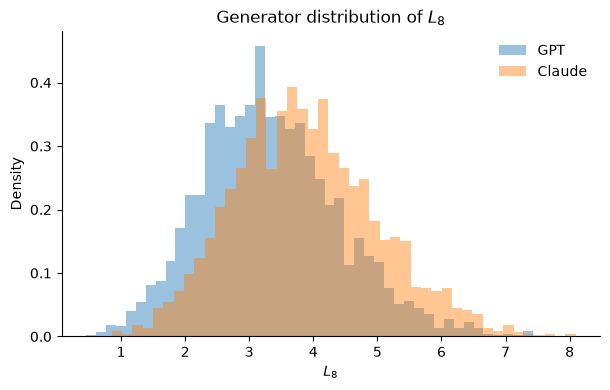

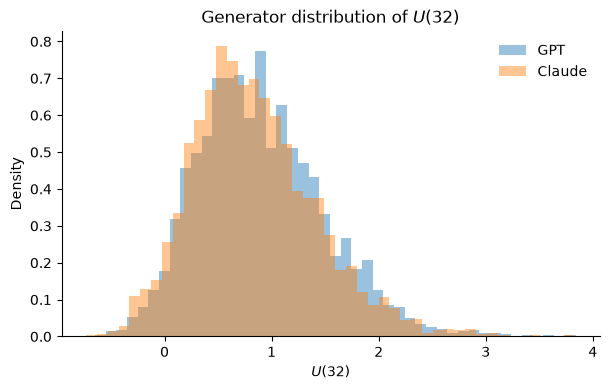

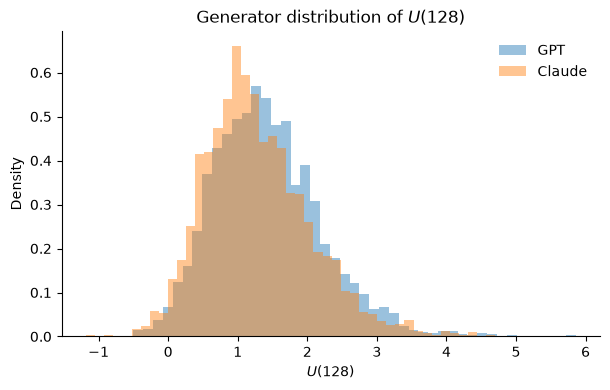

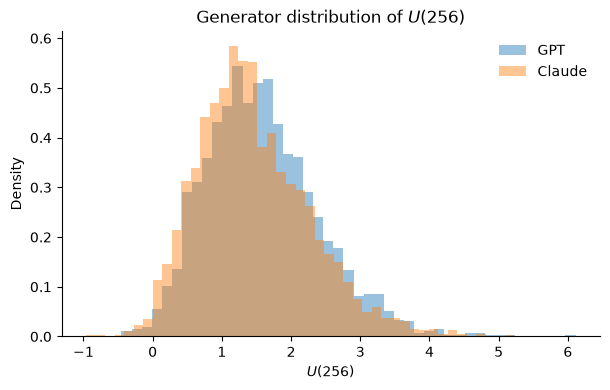

In [9]:
pretty={"context_loss_8":r"$L_8$","context_u_32":r"$U(32)$","context_u_128":r"$U(128)$","context_u_256":r"$U(256)$"}
for f in INSPECT:
    fig,ax=plt.subplots(figsize=(6.2,4.0))
    for g in ["gpt","claude"]:
        vals=work.loc[work["generator"]==g,f].dropna()
        ax.hist(vals,bins=45,density=True,alpha=.45,label=("GPT" if g=="gpt" else "Claude"))
    ax.set_xlabel(pretty[f]); ax.set_ylabel("Density"); ax.set_title(f"Generator distribution of {pretty[f]}")
    ax.legend(frameon=False); ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    fig.tight_layout()
    stem=f.replace("context_","")
    fig.savefig(FIGURES/f"context_profile_distribution_{stem}.pdf",bbox_inches="tight")
    fig.savefig(FIGURES/f"context_profile_distribution_{stem}.png",dpi=200,bbox_inches="tight")
    plt.show()


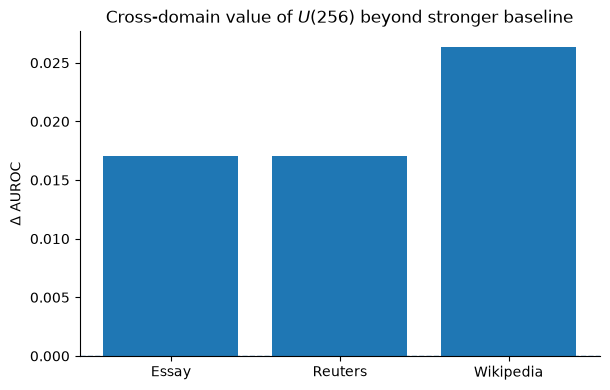

In [10]:
headline=transfer_deltas[transfer_deltas["comparison"]=="Bstrong+U256 vs Bstrong"].copy()
fig,ax=plt.subplots(figsize=(6.2,4.0))
x=np.arange(len(headline))
ax.bar(x,headline["delta_auroc"].to_numpy())
ax.axhline(0,linestyle="--",linewidth=1)
ax.set_xticks(x); ax.set_xticklabels(headline["heldout_domain_label"].tolist())
ax.set_ylabel(r"$\Delta$ AUROC")
ax.set_title(r"Cross-domain value of $U(256)$ beyond stronger baseline")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES/"context_profile_cross_domain_transfer.pdf",bbox_inches="tight")
fig.savefig(FIGURES/"context_profile_cross_domain_transfer.png",dpi=200,bbox_inches="tight")
plt.show()


## Interpretation

The strongest cheap robustness pattern would be:

- `Bstrong+U256 > Bstrong` on most/all source-held-out splits;
- the same contrast is positive in all three held-out-domain transfers;
- \(U(256)\) is not nearly redundant with \(L_8\);
- the full \(C\) profile still adds little beyond \(U(256)\).

That would support the narrow claim that long-range context utility carries generator-specific information beyond short-context loss and a reasonably broad set of transparent lexical/style controls, including under domain transfer.


In [11]:
def fs(x): return f"{x:+.5f}"

print("SOURCE-HELD-OUT")
for comp in ["Bstrong+U256 vs Bstrong","Bstrong+C vs Bstrong","Bstrong+C vs Bstrong+U256"]:
    r=source_summary[(source_summary["comparison"]==comp)&(source_summary["metric"]=="auroc")].iloc[0]
    print(comp,"| mean",fs(r.mean_delta),"| median",fs(r.median_delta),
          "| IQR",f"[{fs(r.q25)}, {fs(r.q75)}]","| positive",f"{int(r.positive)}/{int(r.n)}")

print("\nCROSS-DOMAIN")
h=transfer_deltas[transfer_deltas["comparison"]=="Bstrong+U256 vs Bstrong"]
for r in h.itertuples(index=False):
    print(r.heldout_domain_label,"| ΔAUROC",fs(r.delta_auroc),
          "| ΔBalAcc",fs(r.delta_balanced_accuracy),"| ΔF1",fs(r.delta_f1))

print("\nCORRELATIONS WITH U256")
for f in ["context_loss_8","context_u_32","context_u_128"]:
    print(f,"| Pearson",f"{pearson.loc[f,'context_u_256']:.4f}",
          "| Spearman",f"{spearman.loc[f,'context_u_256']:.4f}")


SOURCE-HELD-OUT
Bstrong+U256 vs Bstrong | mean +0.01467 | median +0.01436 | IQR [+0.01191, +0.01654] | positive 20/20
Bstrong+C vs Bstrong | mean +0.01489 | median +0.01553 | IQR [+0.01104, +0.01720] | positive 20/20
Bstrong+C vs Bstrong+U256 | mean +0.00022 | median +0.00028 | IQR [-0.00021, +0.00086] | positive 13/20

CROSS-DOMAIN
Essay | ΔAUROC +0.01706 | ΔBalAcc +0.01500 | ΔF1 +0.04009
Reuters | ΔAUROC +0.01702 | ΔBalAcc +0.04073 | ΔF1 +0.02156
Wikipedia | ΔAUROC +0.02636 | ΔBalAcc +0.02506 | ΔF1 +0.04016

CORRELATIONS WITH U256
context_loss_8 | Pearson 0.5790 | Spearman 0.5538
context_u_32 | Pearson 0.7077 | Spearman 0.7050
context_u_128 | Pearson 0.9384 | Spearman 0.9333
